In [1]:
"""
Define of all the unit:
CGS system
P in units of eng * cm **-3
T_1 in unit of k
m in unit of g
rho in unit of g cm **-3
metallicity in units of solar metallicity
kB​=1.380649e−16 erg* K**-1
Problem: inconsistant kb definition
"""


'\nDefine of all the unit:\nCGS system\nP in units of eng * cm **-3\nT_1 in unit of k\nm in unit of g\nrho in unit of g cm **-3\nmetallicity in units of solar metallicity\nkB\u200b=1.380649e−16 erg* K**-1\nProblem: inconsistant kb definition\n'

In [2]:
"""
Define of all constant:
CGS system
"""
import numpy as np
import matplotlib.pyplot as plt
mu = 0.62
muH = 1/0.75
kb = 1.380649e-16
gamma = 5/3
Z_solar = 0.02
mH = 1.673536 * 10**(-24)
H0 = 2.27e-18
Om_r = 9e-5
Om_m = 0.31
Om_l = 0.69
G = 6.674e-8

In [3]:
"""
define the function between virial mass and virial temp
"""
def T_vir(M_vir, z):
  rho_c = 3* H0**2 * (Om_r * (1 + z)**4 + Om_m* (1 + z)**3 + Om_l )/(8* np.pi * G)
  r_vir = (3* M_vir /(4 * np.pi * rho_c * 200))**(1/3)
  T_vir = mu * mH * G * M_vir / (r_vir * kb)
  return T_vir

In [4]:
print(T_vir(5.6e43, 0))
print(T_vir(4e42, 0))

145107.5084353997
24980.69563780861


In [5]:
"""
set up: cooling function lambda
"""
import h5py
from scipy import interpolate
Cooling_File = "z_0.000.hdf5" ### From Wiersma et al. (2009) appropriate for z=0 UVB
f = h5py.File(Cooling_File, 'r')
i_X_He = -3
Metal_free   = f.get('Metal_free')
Total_Metals = f.get('Total_Metals')
log_Tbins    = np.array(np.log10(Metal_free['Temperature_bins']))
log_nHbins   = np.array(np.log10(Metal_free['Hydrogen_density_bins']))
Cooling_Metal_free   = np.array(Metal_free['Net_Cooling'])[i_X_He] ##### what Helium_mass_fraction to use    Total_Metals = f.get('Total_Metals')
Cooling_Total_Metals = np.array(Total_Metals['Net_cooling'])
HHeCooling           = interpolate.RectBivariateSpline(log_Tbins,log_nHbins, Cooling_Metal_free)
ZCooling             = interpolate.RectBivariateSpline(log_Tbins,log_nHbins, Cooling_Total_Metals)
Zs          = np.logspace(-2,1,31)
f.close()
Lambda_tab  = np.array([[[HHeCooling.ev(lT,ln)+Z*ZCooling.ev(lT,ln) for Z in Zs] for lT in log_Tbins] for ln in log_nHbins])
# cooling time is dependent on initial temp and the number density.
Lambda_z0 = interpolate.RegularGridInterpolator((log_nHbins,log_Tbins,Zs), Lambda_tab, bounds_error=False, fill_value=-1e-30)
# why there is out put of nan: is there anything wrong with the interpolation.

In [37]:
# look up the log_nHbins, bound error, and fill_value, check the range of the cooling table
print(max(1, 2))

2


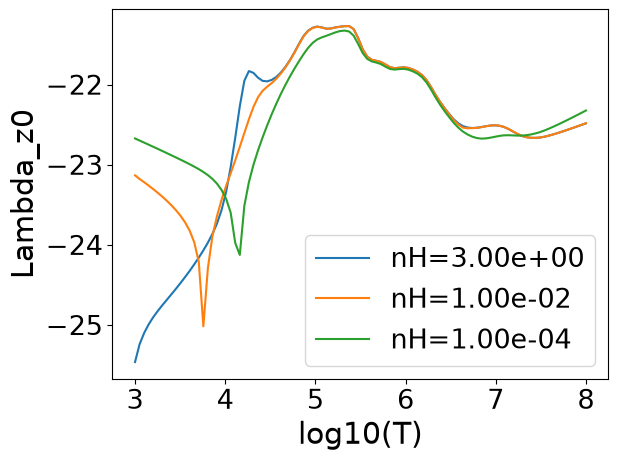

In [46]:
n = np.array((3, 1e-2, 1e-4))
nH_actual = n*(mu/muH)
T = np.linspace(3, 8, 100)
for n_i in n:
    plt.plot(T, np.log10(abs(Lambda_z0((min((np.log10(n_i*(mu/muH))),0), T, 1)))), label=f'nH={n_i:.2e}')
plt.xlabel('log10(T)')
plt.ylabel('Lambda_z0')
plt.legend()
plt.show()
# the data is not usable for n > 3 (2.15 actually)

In [8]:
"""
function of cooling time
"""
def tcool_P(T,n, metallicity):
  """
  cooling time function
  T in units of K
  P in units of K * cm **-3
  metallicity in units of solar metallicity
  returning time is log10(s)
  """
  T = np.where(T>10**8.98, 10**8.98, T)
  T = np.where(T<10**2, 10**2, T)
  nH_actual = n*(mu/muH)
  # n here is the total number density as well, but we convert total number density to hydrogen number density
  nH = np.where(nH_actual>100, 100, nH_actual)
  nH = np.where(nH<10**-8, 10**-8, nH)
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))
# why I think it should be n instead of nH


/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/4031858294.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))
/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/2699243359.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=16)


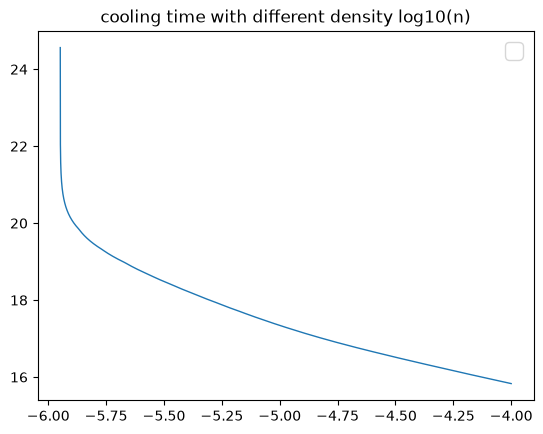

In [9]:
"""
plot of cooling time and initial number density
"""
n_range = np.linspace(-6,-4, 10000)
T_1 = 10**(5)
metallicity = 0.3
y = tcool_P(T_1, 10**n_range, metallicity)
plt.plot(n_range, y, linewidth=1)
plt.title("cooling time with different density log10(n)")
plt.legend(fontsize=16)


In [10]:
"""
First application:
For 2D plot with dimensions of T and n, the specific values of n and T to give the same cooling time(1e18)
"""
import numpy as np

T_range = np.linspace(4, 7, 5000)
n_range = np.linspace(-6, 0, 5000)

metallicity = 0.3
t_H = 1e17
log_tH = np.log10(t_H)

pairs_n = []
for ti in T_range:
    tcool_vals = tcool_P(10**ti, 10**n_range, metallicity)
    mask = (
        (tcool_vals - log_tH >= np.log10(0.999)) &
        (tcool_vals - log_tH < np.log10(1.001))
    )
    n_col = n_range[mask]
    if n_col.size > 0:
        pairs_n.extend([(ti, ni) for ni in n_col])
T_n_H = [p[0] for p in pairs_n]
n_H = [p[1] for p in pairs_n]
from scipy.interpolate import interp1d
bottom_func = interp1d(T_n_H, n_H, kind = 'cubic', fill_value="extrapolate")

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/4031858294.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity)).squeeze()))


In [11]:
"""
For 2D plot with dimensions of T and n, the specific values of n and T to give the same cooling time(1e16 & 1e15)
"""
from scipy.optimize import root_scalar
t_range = np.array((1e16, 3e16))
T_range = np.linspace(4, 7, 2000)
metallicity = 0.3
data = {}
for ti in t_range:
    data[ti] = []
    for Ti in T_range:
        def tcool_midel(x):
          return tcool_P(10**Ti, 10**x, metallicity) - np.log10(ti)
        if tcool_midel(bottom_func(Ti))*tcool_midel(0) <= 0:
          solution = root_scalar(tcool_midel, bracket = [bottom_func(Ti), 0], method='brentq')
          data[ti].append((Ti, solution.root))
T_16, n_16 = zip(*data[1e16])
T_3e16, n_3e16 = zip(*data[3e16])

8.720545860512996


/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/1557976247.py:17: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH),np.log10(T), metallicity)) * nH**2 / (gamma* (P))


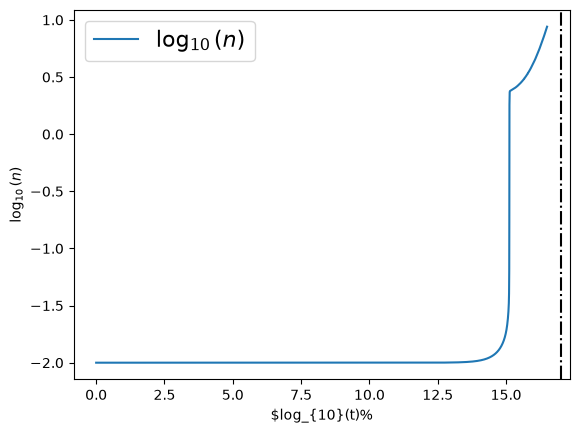

In [12]:
"""
Second appliacation: continuous cooling process with varying pressure(constant positive slope)
For a single point with initial value: T = 1e5, n = 1e-4, kai = 4, integration time = 1e17, monoatomic gas
The plot of log10(n) changing with log10(t)
"""
# note that the K here is defined to be T/(n)**(gamma - 1)
metallicity = 0.3
kai = 4
t_end = 3*10**(16)
n0 = 10**(-2)
T0 = 10**(6)
P0 = kb * n0 * T0
def cont_cool(t, n, period):
  P = P0 + P0* (kai - 1)/period * t
  T = P/(kb * n)
  nH = min((mu/ muH) * n, 1)
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH),np.log10(T), metallicity)) * nH**2 / (gamma* (P))
  return result
def cont_cool_no_radi(t, n, period):
  P = P0 + P0* (kai - 1)/period * t
  T = P/(kb * n)
  nH = (mu/ muH) * n
  result = n * (kai - 1)* P0 /(gamma * period * P)
  return result
from scipy.integrate import solve_ivp
list1 = list(np.arange(0, 1, 0.1))
list2 = list(10**np.linspace(0, 16.5, 10000))
list1.extend(list2)
t_span = np.array(list1)
result = solve_ivp(lambda t, n: cont_cool(t, n, t_end), [t_span[0], t_span[-1]], [n0], t_eval= t_span)
result_n = solve_ivp(lambda t, n: cont_cool_no_radi(t, n, t_end), [t_span[0], t_span[-1]], [n0], t_eval= t_span)
n = result.y[0, :]
n_n = result_n.y[0, :]
plt.plot(np.log10(t_span[10: ]), np.log10(result.y[0, :])[10:], label = r"$\log_{10}(n)$")
plt.xlabel(r"$log_{10}(t)%")
plt.ylabel(r"$\log_{10}(n)$")
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
#ax.xaxis.set_minor_locator(MultipleLocator(1e14))
#plt.axvline(x = 1e14, linestyle = "--", label  = r" t = $10^{14}$s")
plt.legend(fontsize=16)
plt.axvline(x = 17, color =  "black", linestyle = "-." )
print(result.y[0, :][-1])

In [13]:
Lambda_z0((np.log10(100),np.log10(1e6), metallicity))

array(-1.e-30)

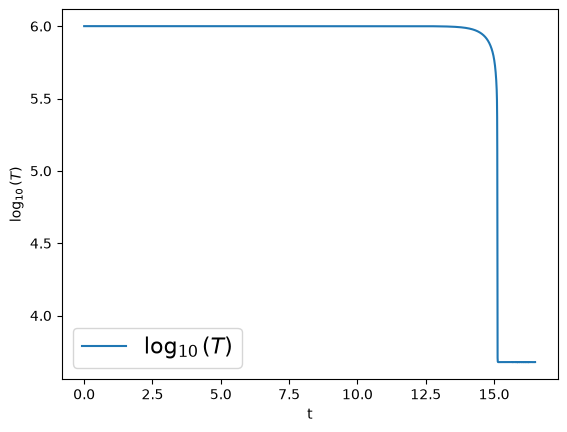

In [14]:
"""
Single poit simulation: log10(T) Vs log10(t) 
"""
P = P0 + P0 * (kai - 1)/t_end * t_span
T = P/(kb * n)
T_n = P/(kb * n_n)
plt.plot(np.log10(t_span[10: ]), np.log10(T)[10: ], label = r"$\log_{10}(T)$")
plt.xlabel("t")
plt.ylabel(r"$\log_{10}(T)$")
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
# ax.xaxis.set_minor_locator(MultipleLocator(1e14))
# plt.axvline(x = 1e14, linestyle = "--", label  = r" t = $10^{14}$s")
plt.legend(fontsize=16)

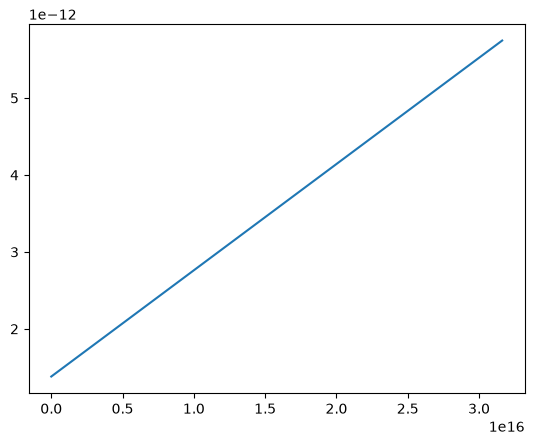

In [15]:
"""
single point similaiton: P vs. t
"""
P = P0 + P0 * (kai - 1)/t_end * t_span
plt.plot(t_span, P, label = r"$\log_{10}(T)$")

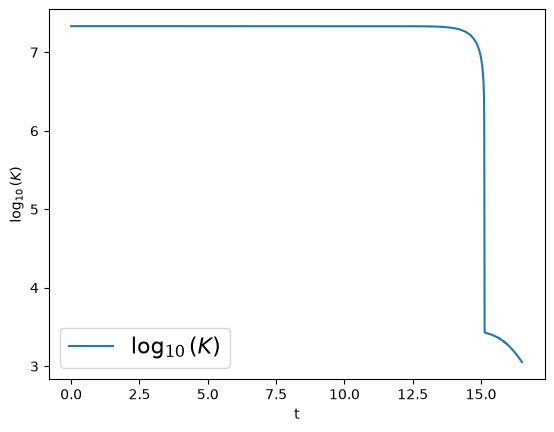

In [16]:
"""
sigle point simulation: log10(entropy) vs. log10(t)
"""
K = T / n**(2/3)
plt.plot(np.log10(t_span[10: ]), np.log10(K)[10: ], label = r"$\log_{10}(K)$")
plt.xlabel("t")
plt.ylabel(r"$\log_{10}(K)$")
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
#ax.xaxis.set_minor_locator(MultipleLocator(1e14))
#plt.axvline(x = 1e14, linestyle = "--", label  = r" t = $10^{14}$s")
plt.legend(fontsize=16)
# kai is almost invariant --→ we can use adiabatic process to approximate

In [47]:
"""
Redefine the function to simulate continuous cooling:
cont_radi defines an ODE of changing density: dn /dt = func
cool_radiation defines an function that outputs an array of # density that envolves with time given initial condition
for function contains "n", they are the function do not consider radiation.
"""
def cont_radi(t, n, P0, kai, period):
  P = P0 + P0* (kai - 1)/period * t
  T = P/(kb * n)
  nH = min((mu/ muH) * n, 1)
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))
  return result
def cont_no_radi(t, n, P0, kai, period):
  P = P0 + P0* (kai - 1)/period * t
  T = P/(kb * n)
  nH = (mu/ muH) * n
  result = n * (kai - 1)* P0 /(gamma * period * P)
  return result

def cool_radiation(n0, T0, kai, metallicity, period):
  """
  The func that gives the density ratia for a given period with radiation
  """
  P0 = kb * n0 * T0
  t_span = np.linspace(0, period, 1000)
  t_end = period
  result = solve_ivp(lambda t, n: cont_radi(t, n, P0, kai, period), [t_span[0], t_span[-1]], [n0], t_eval= t_span)
  P_end = kai * P0
  n_end = result.y[0, :][-1]
  return np.log10(n_end)
def cool_no_radi(n0, T0, kai, metallicity, period):
  """
  The func that gives the cooling time for a given period without radiation
  """
  n0 = n0
  T0 = T0
  P0 = kb * n0 * T0
  t_span = np.linspace(0, period, 1000)
  t_end = period
  result = solve_ivp(lambda t, n: cont_no_radi(t, n, P0, kai, period), [t_span[0], t_span[-1]], [n0], t_eval= t_span)
  P_end = kai * P0
  n_end = result.y[0, :][-1]
  return np.log10(n_end)

In [48]:
"""
Define the function of density difference (initial and final)
"""
def dens_diff_no(n0, T0, kai, metallicity, period):
  return cool_no_radi(n0, T0, kai, metallicity, period) - np.log10(n0)
def dens_diff_rad(n0, T0, kai, metallicity, period):
  return cool_radiation(n0, T0, kai, metallicity, period) - np.log10(n0)
def entropy_diff(n0, T0, kai, metallicity, period):
  """
  The function that gives the entropy ratio for a given period with radiation
  """
  P0 = kb * n0 * T0
  P_end = kai * P0
  n_end = 10** cool_radiation(n0, T0, kai, metallicity, period)
  T_end = P_end/(kb * n_end)
  K_end = T_end / n_end**(2/3)
  K_start = T0 / n0**(2/3)
  return np.log10(K_start/K_end)

In [19]:
print(entropy_diff(10**(-4.5), 10**(4.5), 4, 0.3, 3e16))
print(cool_radiation(10**(-4.5), 10**(4.5), 4, 0.3, 3e16))

0.37744239821876074
-3.912298566271966


In [20]:
"""
Test code: Check that the results of the above functions are the same to the single simulation
"""
def cool_radiation(n0, T0, kai, metallicity, period):
  """
  The func that gives the density ratia for a given period with radiation
  """
  P0 = kb * n0 * T0
  t_span = np.linspace(0, period, 1000)
  t_end = period
  result = solve_ivp(lambda t, n: cont_radi(t, n, P0, kai, period), [t_span[0], t_span[-1]], [n0], t_eval= t_span)
  P_end = kai * P0
  n_end = result.y[0, :][-1]
  return np.log10(n_end)
kai = 4
metallicity = 0.3
period = 1e16
n0 = 10**(-1)
T0 = 10** (5)
P0 = kb * n0 * T0
t_span = np.linspace(0, period, 1000)
print(solve_ivp(lambda t, n: cont_radi(t, n0, P0, kai, period), [t_span[0], t_span[-1]], [n0], t_eval= t_span).y[0, :][-1])
#print(dens_diff_rad(n0, T0, kai, metallicity, period))

46.52901917219867


In [21]:
"""
example case:
For case of specific kai and T0 and varying # density, see how (final density - initial density) changes
the y axis is the ratia of density before and after the compression
x axis is the initial density
P = Kb * n * T
"""
n_range = np.linspace(-6, 0, 200)
kai = 4
T0 = 10** (5.5)
P0 = kb * n0 * T0
period = 1e17
y = np.array([dens_diff_rad(n, T0, kai, metallicity, period) for n in 10**n_range])

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))


/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/1068916400.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=16)
/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/1068916400.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=16)


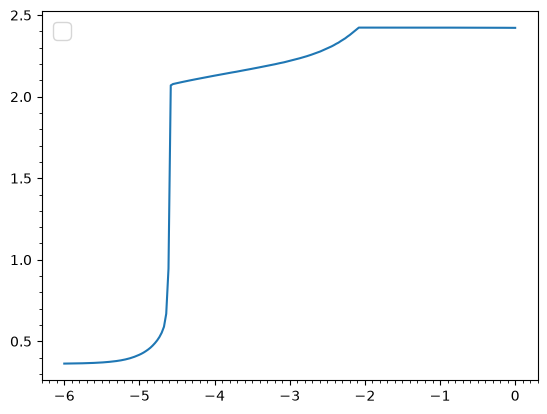

In [22]:
"""
Plot of above data
confusion: why the ratio drops when density is high enough?
"""
plt.plot(n_range, y )
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
plt.legend(fontsize=16)
plt.legend(fontsize=16)
plt.show()

In [23]:
"""
adiabatic transition
"""
def adi_tran(n1, T1, ka):
  """
  ka is p2/p1
  """
  T2 = T1 * ka ** ((gamma-1)/gamma)
  n2 = n1 * ka ** (1/gamma)
  return n2, T2

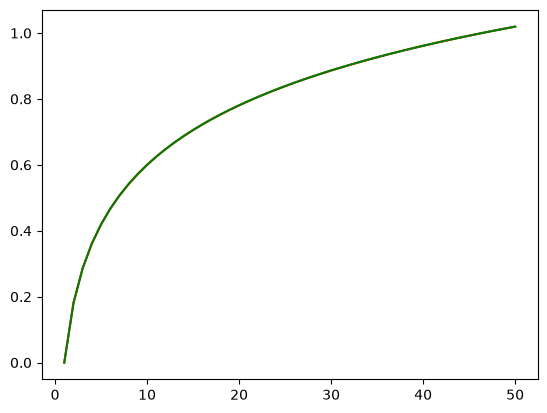

In [24]:
"""
Comparison between adi transition and continuous cooling with no radiation for same initial value with varying kai: 
Satisfy expectation: adiabatic transition is the same to continuous cooling compression with the same kai
"""
n0 = 1e-4
T0 = 1e5
metallicity = 0.3
kai = np.linspace(1, 50, 50)
n2_radi, T2_radi = adi_tran(n0, T0, kai)
period = 1e18
n2_cont_diff = [dens_diff_no(n0, T0, kai_i, metallicity, period) for kai_i in kai]
plt.plot(kai, np.log10(n2_radi) - np.log10(n0), 'r')
plt.plot(kai, n2_cont_diff, 'g')


In [25]:
"""
Follwing code check the influence of the kai on density ratio with specific initial condition,
Comparison with adiabatic transition then cool
T = 1e5
n = 1e-4, 1e-4.5, 1e-5, 1e-5.5, 1e-6
kai is ranging from 1 to 30
integration time is 3e16
"""
T0 = 10**(5)
metallicity = 0.3
period = 3e16
n_range = [10**(-4.8), 10**(-5.5), 10**(-5.1), 10**(-5.2), 10**(-5), 10**(-4)]
kai_range = np.linspace(1, 30, 50)
data = {}
for n_i in n_range:
    data[f"cont{n_i}"] = []
    data[f"adi{n_i}"] = []
for n_i in n_range:
    for kai_i in kai_range:
        n2 , T2 = adi_tran(n_i, T0, kai_i)
        data[f"cont{n_i}"].append(dens_diff_rad(n_i, T0, kai_i, metallicity, period))
        data[f"adi{n_i}"].append(cool_radiation(n2, T2, 1, metallicity, period) - np.log10(n_i))

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))


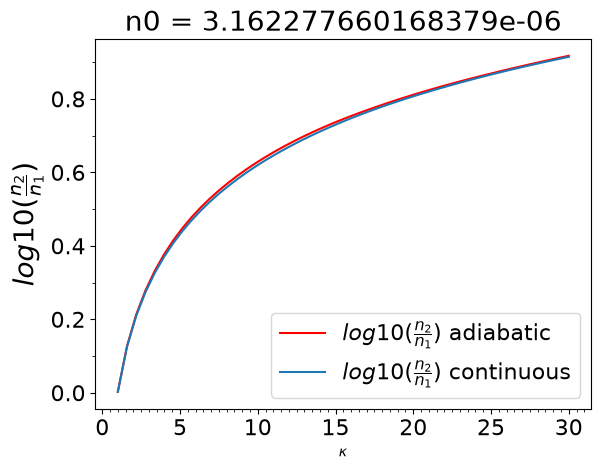

In [26]:
import matplotlib.pyplot as plt
import numpy as np
n0 = 10**(-5.5)
plt.plot(kai_range, data[f"adi{n0}"], "r", label = r"$log10(\frac{n_2}{n_1})$ adiabatic") #
plt.plot(kai_range, data[f"cont{n0}"], label = r"$log10(\frac{n_2}{n_1})$ continuous")
plt.xlabel(r"$\kappa$")  
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
plt.title(f"n0 = {n0}", fontsize=20)
plt.ylabel(r"$log10(\frac{n_2}{n_1})$", fontsize=20)
plt.legend(fontsize=16)

In [27]:
"""
Follwing code check the influence of the kai on density ratio with specific initial condition,
Comparison with adiabatic transition then cool
T = 1e5
n = 1e-4, 1e-4.5, 1e-5, 1e-5.5, 1e-6
kai is ranging from 1 to 30
integration time is 3e16
"""
T0 = 10**(5)
metallicity = 0.3
period = 3e16
n_range = [10**(-6), 10**(-5.5), 10**(-5.1), 10**(-5.2), 10**(-5), 10**(-4)]
kai_range = np.linspace(1, 30, 50)

data = {}
for n_i in n_range:
    data[f"cont{n_i}"] = []
    data[f"adi{n_i}"] = []
for n_i in n_range:
    for kai_i in kai_range:
        n_after = 10**cool_radiation(n_i, T0, kai_i, metallicity, period)
        n_after_no = 10**cool_radiation(n_i, T0, 1, metallicity, period)
        T_after = kai_i * T0 * n_i / n_after 
        T_after_no = 1 * T0 * n_i / n_after_no 
        data[f"cont{n_i}"].append(2/3 * (np.log10(n_after) - np.log10(n_i)) + np.log10(T0/ T_after)) # entropy bef. cooling / entro aft. cooling
        data[f"adi{n_i}"].append(2/3 * (np.log10(n_after_no) - np.log10(n_i)) + np.log10(T0/ T_after_no ))

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))


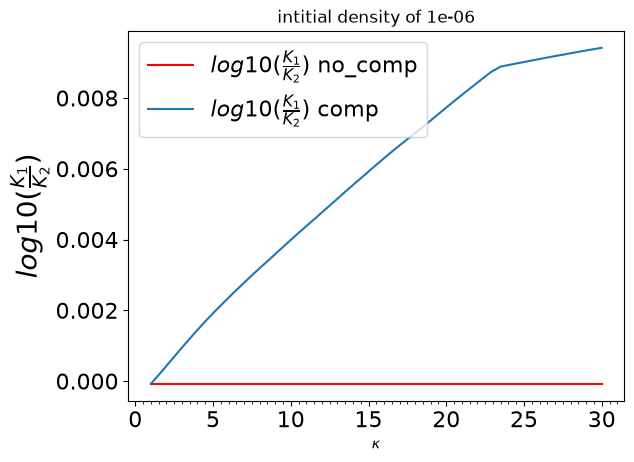

In [28]:
import matplotlib.pyplot as plt
import numpy as np
n0 = 10**(-6)
plt.plot(kai_range, data[f"adi{n0}"], "r", label = r"$log10(\frac{K_1}{K_2})$ no_comp") #
plt.plot(kai_range, data[f"cont{n0}"], label = r"$log10(\frac{K_1}{K_2})$ comp")
plt.xlabel(r"$\kappa$")  
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
plt.ylabel(r"$log10(\frac{K_1}{K_2})$", fontsize=20)
plt.title(f"intitial density of {n0}")
plt.legend(fontsize=16)

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.colorbar import ColorbarBase
n = 8
shades = cm.Blues(np.linspace(0.2, 1.0, n))  
cmap = colors.ListedColormap(shades)
bounds = np.arange(-0.5, n)                   # bin edges: -0.5, 0.5, ..., 4.5
norm = colors.BoundaryNorm(bounds, cmap.N)


/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3270272651.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


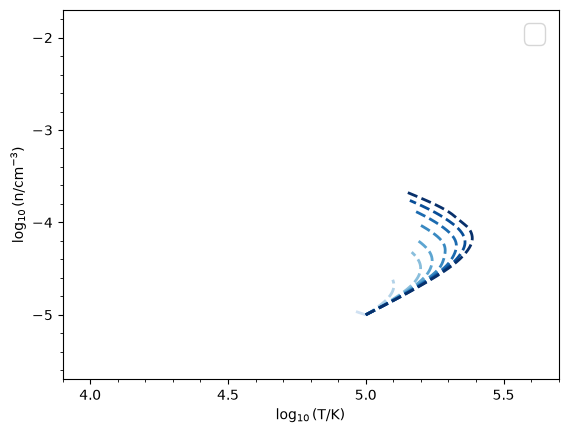

<Figure size 600x450 with 0 Axes>

In [30]:
"""
Simulation of a single point n and T evolving with time with different kai for 1 Gyr
Initial condition:
n = 1e-5, T = 1e5, metallicity = 0.3, period =  3e16
"""
def cool_radiation_single(n0, T0, kai, metallicity, period):
  """
  The func that gives the density ratia for a given period with radiation
  """
  P0 = kb * n0 * T0
  t_span = np.linspace(0, period, 10000)
  t_end = period
  result = solve_ivp(lambda t, n: cont_radi(t, n, P0, kai, period), [t_span[0], t_span[-1]], [n0], t_eval= t_span)
  P_end = kai * P0
  p_span = P0 + (- P0 + P_end)/ period * result.t
  n_span = result.y
  T_span = p_span / (kb* n_span)
  return np.log10(n_span), np.log10(T_span)
n0 = 10**(-5)
T0 = 10**(5)
metallicity = 0.3
kai_range = np.array((1, 3, 7, 10, 15, 20, 25, 30))
period = 3e16
data_sin = {}
fig, ax = plt.subplots()
ax.set_xlim(3.9, 5.7)
ax.set_ylim(-5.7, -1.7)
fig = plt.figure(figsize=(6, 4.5))
scale = 6 / 2.5
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
kai_range_list = list(kai_range)
for kai_i in kai_range:
    ind = kai_range_list.index(kai_i)
    p_end = kb * n0 * T0 * kai_i
    x_tmp, y_tmp = cool_radiation_single(n0, T0, kai_i, metallicity, period) # log10(n) and log10(T) at each time
    data_sin[f"{kai_i}n"] = x_tmp[0]
    data_sin[f"{kai_i}T"] = y_tmp[0]
    ax.plot(data_sin[f"{kai_i}T"], data_sin[f"{kai_i}n"], ls='--', lw=2, color=shades[ind]) #, label = f"kai of {kai_i}")
# ax.set_title(r"n = 1e-5 and T = 1e5")
ax.set_xlabel(r"$\log_{10}(\mathrm{T/K})$")
ax.set_ylabel(r"$\log_{10}(\mathrm{n/cm^{-3}})$")

ax.legend()

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/403926516.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


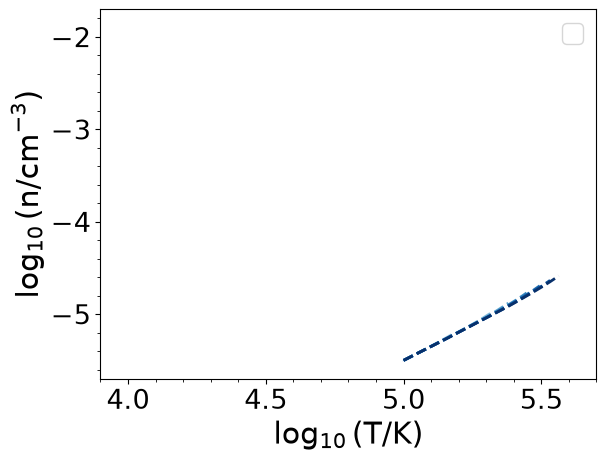

In [31]:
"""
Initial condition:
n = 1e-5.5, T = 1e5, metallicity = 0.3, period =  3e16
"""
n0 = 10**(-5.5)
T0 = 10**(5)
metallicity = 0.3
kai_range = np.array((1, 3, 7, 10, 15, 20, 25, 30))
period = 3* 10**(16)
data_sin2 = {}
fig, ax = plt.subplots()
ax.set_xlim(3.9, 5.7)
ax.set_ylim(-5.7, -1.7)
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
for kai_i in kai_range:
    ind = kai_range_list.index(kai_i)
    p_end = kb * n0 * T0 * kai_i
    x_tmp, y_tmp = cool_radiation_single(n0, T0, kai_i, metallicity, period) # log10(n) and log10(T) at each time
    data_sin2[f"{kai_i}n"] = x_tmp[0]
    data_sin2[f"{kai_i}T"] = y_tmp[0]
    ax.plot(data_sin2[f"{kai_i}T"], data_sin2[f"{kai_i}n"], ls='--', lw=2, color=shades[ind]) # , label = f"kai of {kai_i}")
# plt.title(r"n = 1e-5.5 and T = 1e5")
plt.xlabel(r"$\log_{10}(\mathrm{T/K})$")
plt.ylabel(r"$\log_{10}(\mathrm{n/cm^{-3}})$")
plt.legend()

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/403926516.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


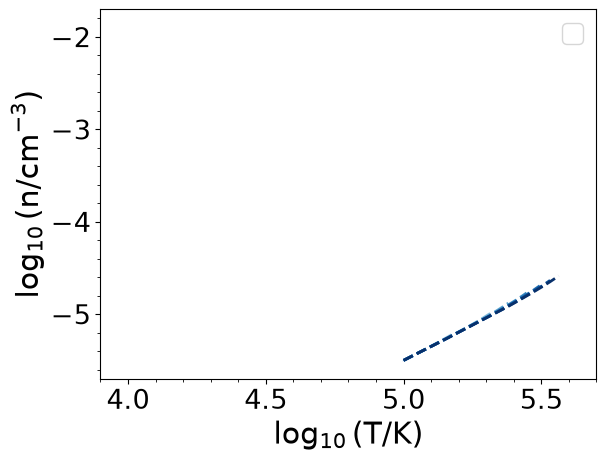

In [32]:
"""
Initial condition:
n = 1e-5.5, T = 1e5, metallicity = 0.3, period =  3e16
"""
n0 = 10**(-5.5)
T0 = 10**(5)
metallicity = 0.3
kai_range = np.array((1, 3, 7, 10, 15, 20, 25, 30))
period = 3* 10**(16)
data_sin2 = {}
fig, ax = plt.subplots()
ax.set_xlim(3.9, 5.7)
ax.set_ylim(-5.7, -1.7)
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
for kai_i in kai_range:
    ind = kai_range_list.index(kai_i)
    p_end = kb * n0 * T0 * kai_i
    x_tmp, y_tmp = cool_radiation_single(n0, T0, kai_i, metallicity, period) # log10(n) and log10(T) at each time
    data_sin2[f"{kai_i}n"] = x_tmp[0]
    data_sin2[f"{kai_i}T"] = y_tmp[0]
    ax.plot(data_sin2[f"{kai_i}T"], data_sin2[f"{kai_i}n"], ls='--', lw=2, color=shades[ind]) # , label = f"kai of {kai_i}")
# plt.title(r"n = 1e-5.5 and T = 1e5")
plt.xlabel(r"$\log_{10}(\mathrm{T/K})$")
plt.ylabel(r"$\log_{10}(\mathrm{n/cm^{-3}})$")
plt.legend()

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))
/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/1866351477.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


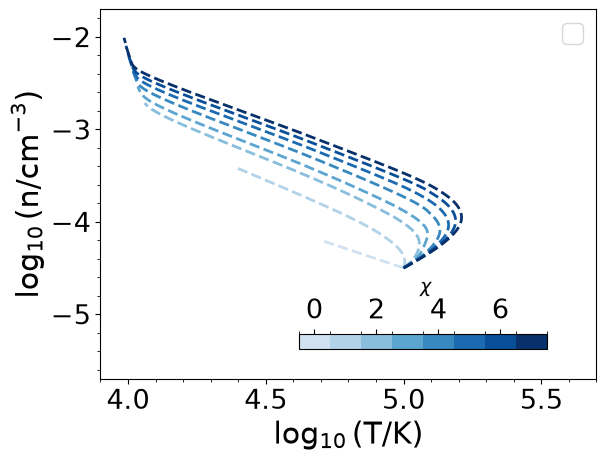

In [33]:
"""
Initial condition:
n = 1e-4.5, T = 1e5, metallicity = 0.3, period =  3e16
"""
n0 = 10**(-4.5)
T0 = 10**(5)
metallicity = 0.3
kai_range = np.array((1, 3, 7, 10, 15, 20, 25, 30))
period = 3*10**(16)
data_sin3 = {}
fig, ax = plt.subplots()
ax.set_xlim(3.9, 5.7)
ax.set_ylim(-5.7, -1.7)
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
for kai_i in kai_range:
    ind = kai_range_list.index(kai_i)
    p_end = kb * n0 * T0 * kai_i
    x_tmp, y_tmp = cool_radiation_single(n0, T0, kai_i, metallicity, period) # log10(n) and log10(T) at each time
    data_sin3[f"{kai_i}n"] = x_tmp[0]
    data_sin3[f"{kai_i}T"] = y_tmp[0]
    ax.plot(data_sin3[f"{kai_i}T"], data_sin3[f"{kai_i}n"], ls='--', lw=2, color=shades[ind]) # , label = f"kai of {kai_i}")
# ax.set_title(r"n = 1e-4.5 and T = 1e5")
cax = ax.inset_axes([0.4, 0.08, 0.5, 0.04])
cb = ColorbarBase(cax, cmap=cmap, norm=norm,
                  orientation='horizontal',
                  ticks=np.arange(0,n, 2 )) 
cax.xaxis.set_ticks_position('top')
cax.xaxis.set_label_position('top')
cb.set_label(r' $\chi$', labelpad=4, fontsize=14)      # ticks at bin centers: 0..4
ax.set_xlabel(r"$\log_{10}(\mathrm{T/K})$")
ax.set_ylabel(r"$\log_{10}(\mathrm{n/cm^{-3}})$")

ax.legend()

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))
/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/918391918.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


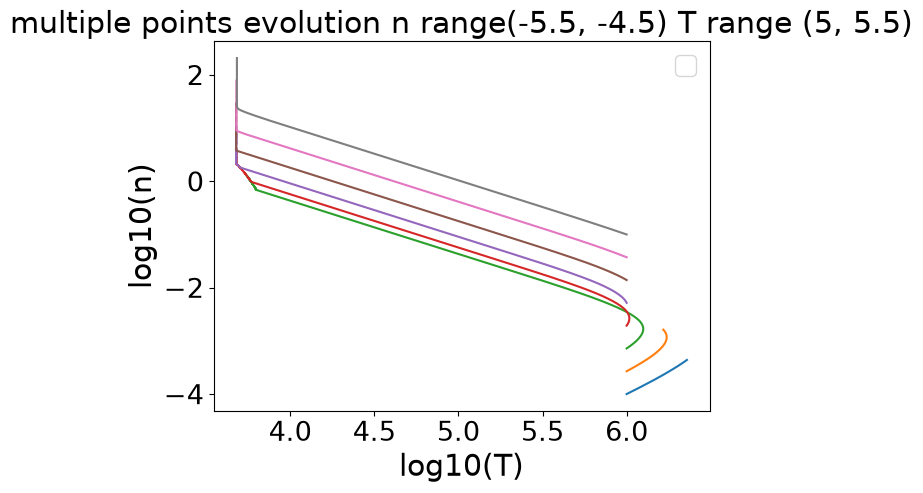

In [34]:
"""
single simulation for multiple points n range(-5.5, -4.5) T range (5, 5.5)
point evolving with time
initial condition:
metallicity = 0.3, kai = 3, period = 3e17
"""
n_range = 10**np.linspace(-4, -1, 8)
T = 10**6
kai = 10
metallicity = 0.3
period = 3e16
data_sin_mul = {}
for n_i in n_range:
        x_tmp, y_tmp = cool_radiation_single(n_i, T, kai, metallicity, period) # log10(n) and log10(T) at each time
        x_tmp2, y_tmp2 = cool_radiation_single(n_i, T, 1, metallicity, period)
        data_sin_mul[f"{n_i}&{T}n"] =  x_tmp[0]
        data_sin_mul[f"{n_i}&{T}T"] =  y_tmp[0]
        data_sin_mul[f"{n_i}&{T}no_comp_n"] =  x_tmp2[0]
        data_sin_mul[f"{n_i}&{T}no_comp_T"] =  y_tmp2[0]
        line, = plt.plot(data_sin_mul[f"{n_i}&{T}T"], data_sin_mul[f"{n_i}&{T}n"])
plt.title("multiple points evolution n range(-5.5, -4.5) T range (5, 5.5)")
plt.xlabel("log10(T)")
plt.ylabel("log10(n)")
plt.legend()

[0.78206873 0.78221652 0.78235954 ... 1.32090672 1.32094762 1.32098862]


/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))


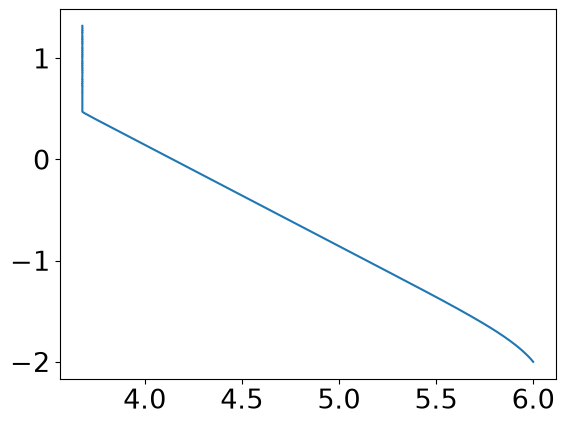

In [35]:
n = 10**(-2)
T = 10**6
kai = 10
metallicity = 0.3
period = 3e16
x_tmp, y_tmp = cool_radiation_single(n, T, kai, metallicity, period)
plt.plot(y_tmp[0], x_tmp[0])
print(x_tmp[0][2100:])

In [49]:
"""
Heat map of # density ratial (n_final/ n_initial) with varying intial # density and temp, calculated using dens_diff_rad
the line contour is the constant cooling curve w/out compression 1e16 and 1e17 (Do we need to include the compression)
kai = 4, metallicity = .3
Time for this plot is 3e16 ~ 1 Gyr, which is reasonable
"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
# Create 1D coordinate arrays
n_range = 10** np.linspace(-6, 0, 20)
T_range = 10** np.linspace(4, 7, 20)
kai = 4
metallicity = 0.3
period = 10**(16)
# Create coordinate grid
T , N= np.meshgrid(T_range, n_range)

Z_data3 = np.zeros_like(T, dtype=float)
Z_data2 = np.zeros_like(T, dtype=float)
Z_data1 = np.zeros_like(T, dtype=float)
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        # all Z_data1, Z_data2, Z_data3, have constant meanings in this program. 
        Z_data1[i, j] = entropy_diff(N[i, j], T[i, j], kai, metallicity, period) # log10 entropy compression with radiative cooling / no radiation

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1359/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))


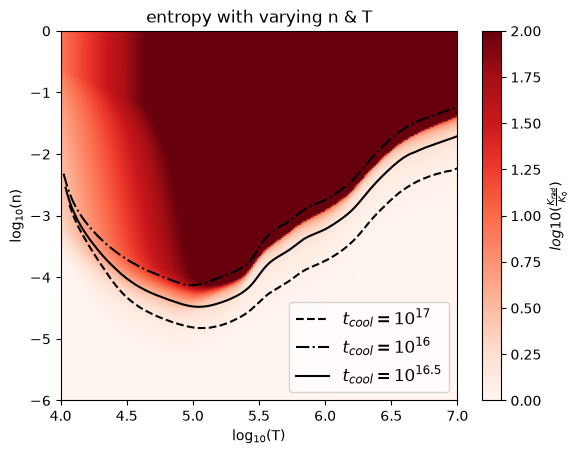

In [ ]:
"""
Plot of the heat map of above data
"""
A = np.max(np.abs(Z_data1))
B = np.min(Z_data1)
# Plot heatmap
plt.imshow(
    Z_data1,
    extent=[np.log10(T_range.min()), np.log10(T_range.max()), np.log10(n_range.min()), np.log10(n_range.max())],
    origin='lower',
    aspect='auto',
    cmap='Reds', # diverging colormap
    vmin= 0,
    vmax= 2
)
plt.colorbar(label=r"$log10(\frac{K_{rad}}{K_0})$")
plt.xlabel(r"log$_{10}$(T)") 
plt.ylabel(r"log$_{10}$(n)") 
plt.title(r"entropy with varying n & T")
plt.plot(T_n_H, n_H, "black", linestyle = "--", label = r"$t_{cool} = 10^{17}$")
plt.plot(T_16, n_16, "black", linestyle = "-." , label = r"$t_{cool} = 10^{16}$")
plt.plot(T_3e16, n_3e16, "black", linestyle = "-" , label = r"$t_{cool} = 10^{16.5}$")
plt.legend(fontsize=12, loc = 'lower right')
plt.show()

In [ ]:
np.savetxt(
    r"D:\Research\columbia\data\kai4_int16\kai_4_1e16_integration_200.dat",
    np.column_stack((T.ravel(), N.ravel(), Z_data1.ravel())),
    header="T, N, Z_data1",
    fmt="%.10e"
)

: 

In [ ]:
"""
Plot of entropy change of the two cases:
the final entropy ratio of cooling with compression and cooling without compression
"""
n_range = 10** np.linspace(-6, 0, 200)
T_range = 10** np.linspace(4, 7, 200)
kai = 4
metallicity = 0.3
period = 3*10**(16)
# Create coordinate grid
T , N= np.meshgrid(T_range, n_range)
Z_data4 = np.zeros_like(T, dtype=float)
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        Z_data4[i, j] = dens_diff_rad(N[i, j], T[i, j], 1, metallicity, period)

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1481/3881234951.py:11: RuntimeWarning: invalid value encountered in log10
  result = n * (kai - 1)* P0 /(gamma * period * P) + (gamma - 1)* n* Lambda_z0((np.log10(nH), np.log10(T), metallicity)) * nH**2 / (gamma* (P))


In [ ]:
"""
data loading of no compression and compression case
"""
data1 = np.loadtxt(r'/Users/yichenwu/Desktop/research/galaxy evolution/data/kai_1_16.5/entropy_change_no_comp.dat', skiprows=1)
n_range = 10** np.linspace(-6, 0, 200)
T_range = 10** np.linspace(4, 7, 200)
T = np.log10(data1[:, 0])
N = np.log10(data1[:, 1])
T = np.unique(T)
N = np.unique(N)
Z_den_nocom = data1[:, 2]
T , N= np.meshgrid(T_range, n_range)
Z_data2 = Z_den_nocom.reshape(len(N), len(T))

data2 = np.loadtxt(r'/Users/yichenwu/Desktop/research/galaxy evolution/data/kai4_16.5/kai4_3e16_integration_200.dat', skiprows=1)
Z_den_com = data2[:, 2]
Z_data1 = Z_den_com.reshape(len(N), len(T))
Entropy_ratio = Z_data1 - Z_data2

/var/folders/c8/xndb31s57_x379vd3zb670mw0000gn/T/ipykernel_1634/2608558998.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12, loc = 'lower right')


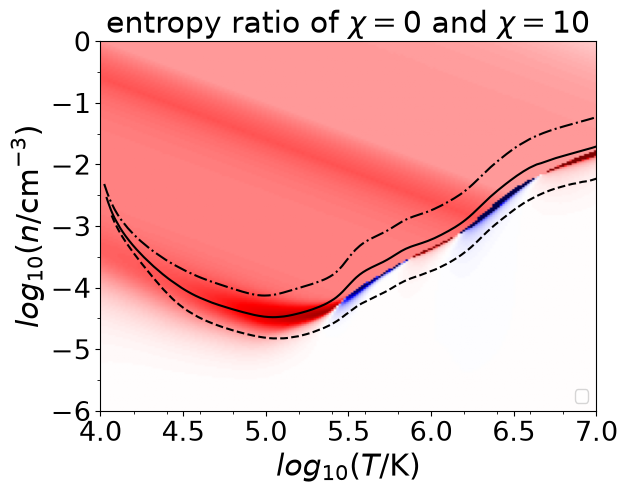

In [ ]:
"""
Plot of entropy ratio of no compression and compression
"""
fig, ax = plt.subplots()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))
plt.imshow(
    Entropy_ratio,
    # Fix: Use log10 of the ranges for the extent to match log labels
    extent=[np.log10(T_range.min()), np.log10(T_range.max()), np.log10(n_range.min()), np.log10(n_range.max())],
    origin='lower',
    aspect='auto',
    cmap='seismic', 
    vmin= -2,
    vmax= 2
)
# plt.colorbar(label=r"$log10(\frac{K_{\chi = 0}}{K_{\chi = 4}})$")
plt.xlabel(r'$log_{10}(T/\mathrm{K})$')
plt.ylabel(r'$log_{10}(n/\mathrm{cm^{-3}})$')
plt.title(r"entropy ratio of $\chi = 0$ and $\chi = 10$")

plt.plot(T_n_H, n_H, "black", linestyle = "--")#, label = r"$t_{cool} = 10^{17}$")
plt.plot(T_16, n_16, "black", linestyle = "-.")# , label = r"$t_{cool} = 10^{16}$")
plt.plot(T_3e16, n_3e16, "black", linestyle = "-")#  , label = r"$t_{cool} = 10^{16.5}$")
plt.legend(fontsize=12, loc = 'lower right')
plt.show()

In [ ]:
"""
np.savetxt(
    r"D:\Research\columbia\data\entopy_change\kai_10_3e16_integration_200_entropy.dat",
    np.column_stack((T.ravel(), N.ravel(), Kai_ratio.ravel())),
    header="T, N, Kai_ratio(K_nocom/ K_com)",
    fmt="%.10e"
)
"""


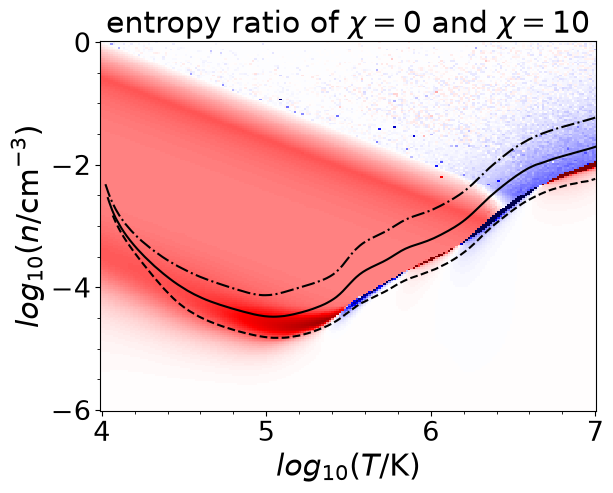

In [ ]:
"""
Heat map of # density ratial (n_final/ n_initial) with varying intial # density and temp, calculated using dens_diff_rad
the line contour is the constant cooling curve w/out compression 1e16 and 1e17 (Do we need to include the compression)

Time for this plot is 1e17 ~ 3.3 Gyr
kai = 4, metallicity = .3
"""
# Read the file (skip the header line)
data = np.loadtxt(r'/Users/yichenwu/Desktop/research/galaxy evolution/data/entopy_change/kai_4_3e16_integration_200_entropy.dat', skiprows=1)

T = np.log10(data[:, 0])
N = np.log10(data[:, 1])
T_unique = np.unique(T)
N_unique = np.unique(N)
Z_17 = data[:, 2]
fig, ax = plt.subplots()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))
T_grid = T.reshape(len(N_unique), len(T_unique))
N_grid = N.reshape(len(N_unique), len(T_unique))
Z_17 = Z_17.reshape(len(N_unique), len(T_unique))
plt.pcolormesh(T_grid, N_grid, Z_17,
               shading='auto',
               cmap='seismic',
               vmin=-2,
               vmax=2)
plt.plot(T_n_H, n_H, "black", linestyle = "--", label = r"$t_{cool} = 10^{17}$")
plt.plot(T_16, n_16, "black", linestyle = "-." , label = r"$t_{cool} = 10^{16}$")
plt.plot(T_3e16, n_3e16, "black", linestyle = "-" , label = r"$t_{cool} = 10^{16.5}$")
plt.title(r"entropy ratio of $\chi = 0$ and $\chi = 10$")
# plt.colorbar(label='Z_17')
plt.xlabel(r'$log_{10}(T/\mathrm{K})$')
plt.ylabel(r'$log_{10}(n/\mathrm{cm^{-3}})$')
# plt.legend(fontsize=16, loc = 'lower right')
plt.show()


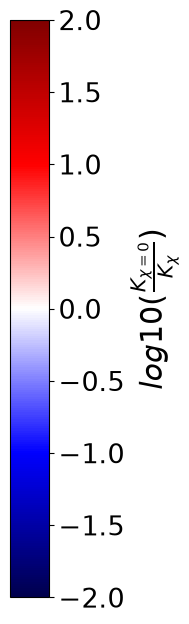

In [ ]:
import matplotlib as mpl

fig, cax = plt.subplots(figsize=(.5, 7.5), constrained_layout=True)

norm = mpl.colors.Normalize(vmin=-2, vmax=2)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='seismic')

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(label=r"$log10(\frac{K_{\chi = 0}}{K_{\chi }})$")


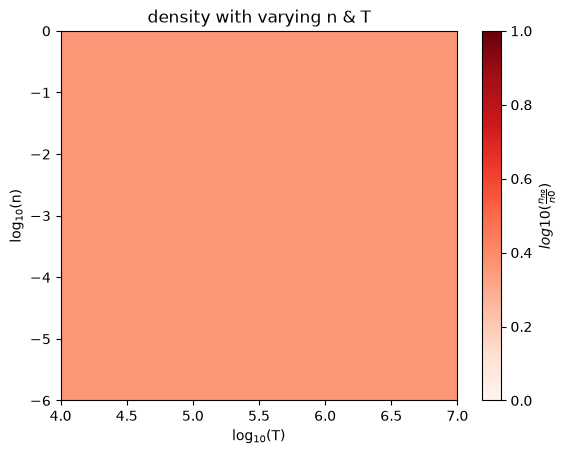

In [ ]:
"""_summary_
Heat map of # density ratial (n_final/ n_initial) with varying intial # density and temp, calculated using dens_diff_no
"""
A = np.max(np.abs(Z_data1))
B = np.min(Z_data1)
# Plot heatmap
plt.imshow(
    Z_data2,
    # Fix: Use log10 of the ranges for the extent to match log labels
    extent=[np.log10(T_range.min()), np.log10(T_range.max()), np.log10(n_range.min()), np.log10(n_range.max())],
    origin='lower',
    aspect='auto',
    cmap='Reds',
    vmin= 0,
    vmax= 2
)
plt.colorbar(label=r"$log10(\frac{n_{no}}{n0})$")
plt.xlabel(r"log$_{10}$(T)") # Fix: Clarify label
plt.ylabel(r"log$_{10}$(n)") # Fix: Clarify label
plt.title(r"density with varying n & T")
# Fix: Remove empty legend
# plt.legend(fontsize=12, loc = 'lower right')
plt.show()

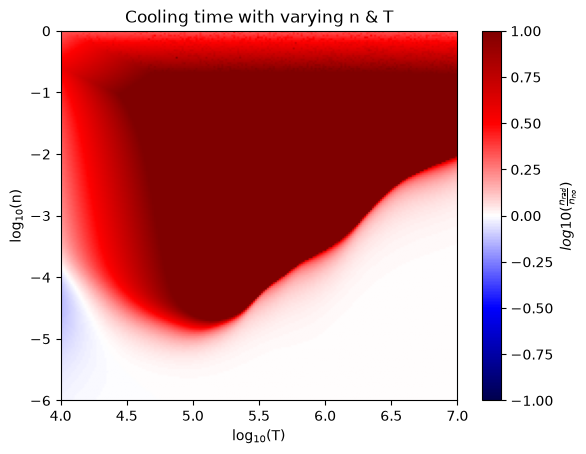

In [ ]:
"""
Heat map of # density ratial (n_rad/ n_no_radi) with varying intial # density and temp, calculated using dens_diff_rad and dens_diff_rad.
"""
A = np.max(np.abs(Z_data3))
B = np.min(Z_data3)
# Plot heatmap
plt.imshow(
    Z_data3,
    # Fix: Use log10 of the ranges for the extent to match log labels
    extent=[np.log10(T_range.min()), np.log10(T_range.max()), np.log10(n_range.min()), np.log10(n_range.max())],
    origin='lower',
    aspect='auto',
    cmap='seismic', # diverging colormap
    vmin= -1,
    vmax= 1
)
plt.colorbar(label=r"$log10(\frac{n_{rad}}{n_{no}})$")
plt.xlabel(r"log$_{10}$(T)") # Fix: Clarify label
plt.ylabel(r"log$_{10}$(n)") # Fix: Clarify label
plt.title(r"Cooling time with varying n & T")
# Fix: Remove empty legend
# plt.legend(fontsize=12, loc = 'lower right')
plt.show()

In [ ]:
"""
Few notes of graphs:
1. convert log10 space to ordinaery space 
2. title and x-y label
3. convert hear map from density ratio to entropy ratio: I think it should be entropy with compression vesus entropy without compression. 
"""